In [2]:
#import libraries
import os
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Semantic color palette
COLOR_PRIMARY   = "#7E57C2"
COLOR_SECONDARY = "#9575CD"
COLOR_DARK      = "#241354"
COLOR_POSITIVE  = "#2E9D6F"
COLOR_NEGATIVE  = "#D64545"
COLOR_HIGHLIGHT = "#F59E0B"
COLOR_NEUTRAL   = "#746A7F"

PALETTE = sns.color_palette(
    [COLOR_DARK, COLOR_PRIMARY, COLOR_SECONDARY, "#B39DDB", "#D1C4E9",
     COLOR_HIGHLIGHT, COLOR_POSITIVE, COLOR_NEUTRAL, "#5E35B1", "#4A148C"]
)

PLOTLY_QUALITATIVE = [COLOR_PRIMARY, COLOR_POSITIVE, COLOR_HIGHLIGHT, COLOR_NEGATIVE,
                       COLOR_SECONDARY, COLOR_DARK, COLOR_NEUTRAL]


def money_fmt(x, pos=None):
    """Format large numbers for chart axes."""
    if abs(x) >= 1e6:
        return f"${x/1e6:,.2f}M"
    if abs(x) >= 1e3:
        return f"${x/1e3:,.0f}K"
    return f"${x:,.0f}"


def money_label(x):
    """Formatter for printed text and tables."""
    if abs(x) >= 1e6:
        return f"${x/1e6:,.2f}M"
    if abs(x) >= 1e3:
        return f"${x/1e3:,.1f}K"
    return f"${x:,.2f}"


In [3]:
#Load Dataset
candidates = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "dataco" in f.lower()]
print("CSV files found in:", candidates)

DATA_PATH = candidates[0] if candidates else "DataCoSupplyChainDataset.csv"
df = pd.read_csv(DATA_PATH, encoding="latin1")

print(f"\nLoaded '{DATA_PATH}' — shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

CSV files found in: ['DataCoSupplyChainDataset.csv']

Loaded 'DataCoSupplyChainDataset.csv' — shape: 180,519 rows x 53 columns


In [4]:
SENSITIVE_COLS = ["Customer Email", "Customer Password", "Customer Fname", "Customer Lname",
                   "Customer Street", "Customer Zipcode"]

SAFE_PREVIEW_COLS = [
    "Order Id", "Customer Id", "order date (DateOrders)", "Product Name", "Category Name",
    "Customer Segment", "Market", "Order Country", "Sales", "Profit",
    "Shipping Mode", "Delivery Status",
]

raw_preview_cols = [c if c != "Profit" else "Benefit per order" for c in SAFE_PREVIEW_COLS]

df[raw_preview_cols].head()

,Order Id,Customer Id,order date (DateOrders),Product Name,Category Name,Customer Segment,Market,Order Country,Sales,Benefit per order,Shipping Mode,Delivery Status
0,77202,20755,1/31/2018 22:56,Smart watch,Sporting Goods,Consumer,Pacific Asia,Indonesia,327.75,91.250000,Standard Class,Advance shipping
1,75939,19492,1/13/2018 12:27,Smart watch,Sporting Goods,Consumer,Pacific Asia,India,327.75,-249.089996,Standard Class,Late delivery
2,75938,19491,1/13/2018 12:06,Smart watch,Sporting Goods,Consumer,Pacific Asia,India,327.75,-247.779999,Standard Class,Shipping on time
3,75937,19490,1/13/2018 11:45,Smart watch,Sporting Goods,Home Office,Pacific Asia,Australia,327.75,22.860001,Standard Class,Advance shipping
4,75936,19489,1/13/2018 11:24,Smart watch,Sporting Goods,Corporate,Pacific Asia,Australia,327.75,134.210007,Standard Class,Advance shipping


In [5]:
df[raw_preview_cols].tail()

,Order Id,Customer Id,order date (DateOrders),Product Name,Category Name,Customer Segment,Market,Order Country,Sales,Benefit per order,Shipping Mode,Delivery Status
180514,26043,1005,1/16/2016 3:40,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,Home Office,Pacific Asia,China,399.980011,40.000000,Standard Class,Shipping on time
180515,26037,9141,1/16/2016 1:34,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,Corporate,Pacific Asia,Japón,399.980011,-613.770019,Second Class,Late delivery
180516,26024,291,1/15/2016 21:00,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,Corporate,Pacific Asia,Australia,399.980011,141.110001,Standard Class,Late delivery
180517,26022,2813,1/15/2016 20:18,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,Consumer,Pacific Asia,Australia,399.980011,186.229996,Standard Class,Advance shipping
180518,26018,7547,1/15/2016 18:54,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,Consumer,Pacific Asia,India,399.980011,168.949997,Standard Class,Shipping on time


In [6]:
print("Shape:", df.shape)
print("\nColumn names:")
for c in df.columns:
    print(" -", c)

Shape: (180519, 53)

Column names:
 - Type
 - Days for shipping (real)
 - Days for shipment (scheduled)
 - Benefit per order
 - Sales per customer
 - Delivery Status
 - Late_delivery_risk
 - Category Id
 - Category Name
 - Customer City
 - Customer Country
 - Customer Email
 - Customer Fname
 - Customer Id
 - Customer Lname
 - Customer Password
 - Customer Segment
 - Customer State
 - Customer Street
 - Customer Zipcode
 - Department Id
 - Department Name
 - Latitude
 - Longitude
 - Market
 - Order City
 - Order Country
 - Order Customer Id
 - order date (DateOrders)
 - Order Id
 - Order Item Cardprod Id
 - Order Item Discount
 - Order Item Discount Rate
 - Order Item Id
 - Order Item Product Price
 - Order Item Profit Ratio
 - Order Item Quantity
 - Sales
 - Order Item Total
 - Order Profit Per Order
 - Order Region
 - Order State
 - Order Status
 - Order Zipcode
 - Product Card Id
 - Product Category Id
 - Product Description
 - Product Image
 - Product Name
 - Product Price
 - Produ

In [7]:
df.dtypes.to_frame(name="Data Type")

,Data Type
Type,str
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,str
Late_delivery_risk,int64
Category Id,int64
Category Name,str
Customer City,str


In [8]:
#Dataset overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [9]:
describe_cols = [c for c in df.columns if c not in SENSITIVE_COLS]
df[describe_cols].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
Sales per customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Classify columns by role to understand the schema before analysis
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
date_like_cols = [c for c in df.columns if "date" in c.lower()]

print(f"Numeric columns ({len(numeric_cols)}):\n{numeric_cols}\n")
print(f"Categorical columns ({len(categorical_cols)}):\n{categorical_cols}\n")
print(f"Date-like columns ({len(date_like_cols)}):\n{date_like_cols}")


Numeric columns (29):
['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Price', 'Product Status']

Categorical columns (24):
['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Name', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Region', 'Order State', 'Order Status', 'Produc

In [11]:
# Validate assumed field relationships instead of guessing from names
checks = {
    "Sales == Price x Quantity": np.allclose(df["Order Item Product Price"] * df["Order Item Quantity"], df["Sales"], atol=1e-2),
    "Customer Id == Order Customer Id": (df["Customer Id"] == df["Order Customer Id"]).all(),
    "Category Id == Product Category Id": (df["Category Id"] == df["Product Category Id"]).all(),
    "Product Card Id == Order Item Cardprod Id": (df["Product Card Id"] == df["Order Item Cardprod Id"]).all(),
    "Benefit per order == Order Profit Per Order": np.allclose(df["Benefit per order"], df["Order Profit Per Order"], atol=1e-2),
}
for k, v in checks.items():
    print(f"{k}: {v}")

Sales == Price x Quantity: True
Customer Id == Order Customer Id: True
Category Id == Product Category Id: True
Product Card Id == Order Item Cardprod Id: True
Benefit per order == Order Profit Per Order: True


In [12]:
# Missing values summary
missing = df.isnull().sum()
missing = missing[missing > 0]
missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Count": missing.values,
    "Missing %": (missing.values / len(df) * 100).round(2),
    "Data Type": [df[c].dtype for c in missing.index],
}).sort_values("Missing Count", ascending=False).reset_index(drop=True)

missing_df


,Column,Missing Count,Missing %,Data Type
0,Product Description,180519,100.00,float64
1,Order Zipcode,155679,86.24,float64
2,Customer Lname,8,0.00,str
3,Customer Zipcode,3,0.00,float64


In [13]:
# Duplicate rows (exact full-row duplicates)
full_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {full_dupes}")

# Duplicate Order Item Id
print(f"Duplicate Order Item Id: {df['Order Item Id'].duplicated().sum()}")

# Repeated Order Id
repeated_order_ids = df['Order Id'].duplicated().sum()
print(f"Rows sharing an Order Id with another row: {repeated_order_ids:,} "
      f"({repeated_order_ids/len(df)*100:.1f}% of rows)")


Exact duplicate rows: 0
Duplicate Order Item Id: 0
Rows sharing an Order Id with another row: 114,767 (63.6% of rows)


In [14]:
# Cardinality of key business dimensions
cardinality = {
    "Unique Orders (Order Id)": df["Order Id"].nunique(),
    "Unique Order Items (rows)": len(df),
    "Unique Customers (Customer Id)": df["Customer Id"].nunique(),
    "Unique Products (Product Card Id)": df["Product Card Id"].nunique(),
    "Unique Categories": df["Category Name"].nunique(),
    "Unique Departments": df["Department Name"].nunique(),
    "Unique Markets": df["Market"].nunique(),
    "Unique Regions": df["Order Region"].nunique(),
    "Unique Countries": df["Order Country"].nunique(),
}
pd.DataFrame(cardinality.items(), columns=["Dimension", "Unique Count"])


,Dimension,Unique Count
0,Unique Orders (Order Id),65752
1,Unique Order Items (rows),180519
2,Unique Customers (Customer Id),20652
3,Unique Products (Product Card Id),118
4,Unique Categories,50
5,Unique Departments,11
6,Unique Markets,5
7,Unique Regions,23
8,Unique Countries,164


In [15]:
# Validity checks on numeric fields
print("Negative Sales rows:", (df["Sales"] < 0).sum())
print("Zero/negative Quantity rows:", (df["Order Item Quantity"] <= 0).sum())
print("Negative Profit rows (real loss-making line items):", (df["Order Profit Per Order"] < 0).sum(),
      f"({(df['Order Profit Per Order'] < 0).mean()*100:.1f}% of rows)")
print("Discount Rate range:", df["Order Item Discount Rate"].min(), "to", df["Order Item Discount Rate"].max())

Negative Sales rows: 0
Zero/negative Quantity rows: 0
Negative Profit rows (real loss-making line items): 33784 (18.7% of rows)
Discount Rate range: 0.0 to 0.25


In [16]:
# Categorical consistency check — look for stray/inconsistent labels
for col in ["Delivery Status", "Order Status", "Shipping Mode", "Customer Segment", "Market", "Type"]:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()


--- Delivery Status ---
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

--- Order Status ---
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

--- Shipping Mode ---
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

--- Customer Segment ---
Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226
Name: count, dtype: int64

--- Market ---
Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614
Name: count, dtype: int64

--- Type ---
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        1

In [17]:
df.groupby("Delivery Status")["Late_delivery_risk"].value_counts().unstack(fill_value=0)

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [18]:
# Date range validity (raw string inspection before parsing)
print("Sample order date strings:", df["order date (DateOrders)"].head(3).tolist())
print("Sample shipping date strings:", df["shipping date (DateOrders)"].head(3).tolist())

Sample order date strings: ['1/31/2018 22:56', '1/13/2018 12:27', '1/13/2018 12:06']
Sample shipping date strings: ['2/3/2018 22:56', '1/18/2018 12:27', '1/17/2018 12:06']


In [19]:
#Data cleaning & preprocessing
rows_before, cols_before = df.shape
missing_before = df.isnull().sum().sum()
dupes_before = df.duplicated().sum()

print("BEFORE CLEANING")
print(f"Rows: {rows_before:,} | Columns: {cols_before} | Missing cells: {missing_before:,} | Duplicate rows: {dupes_before}")


BEFORE CLEANING
Rows: 180,519 | Columns: 53 | Missing cells: 336,209 | Duplicate rows: 0


In [20]:
df_clean = df.copy()

# 1. Parse date columns (format is M/D/YYYY H:MM)
df_clean["order date (DateOrders)"] = pd.to_datetime(df_clean["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
df_clean["shipping date (DateOrders)"] = pd.to_datetime(df_clean["shipping date (DateOrders)"], format="%m/%d/%Y %H:%M")

# 2. Drop columns with no analytical value
cols_to_drop = [
    "Product Description",          # 100% missing
    "Order Customer Id",            # exact duplicate of Customer Id
    "Product Category Id",          # exact duplicate of Category Id
    "Order Item Cardprod Id",       # exact duplicate of Product Card Id
    "Order Profit Per Order",       # exact duplicate of Benefit per order
    "Customer Password",            # PII, already masked, no analytical value
    "Customer Email",               # PII, already masked, no analytical value
    "Customer Fname",               # PII, not used in any analysis below
    "Customer Lname",               # PII, not used in any analysis below
    "Customer Street",              # PII (full street address), not used below
    "Customer Zipcode",             # PII-adjacent, not used below
    "Product Image",                # image URL, not needed for analysis
]
df_clean = df_clean.drop(columns=cols_to_drop)

# 3. Standardize text fields (strip whitespace)
text_cols = df_clean.select_dtypes(include="object").columns
for c in text_cols:
    df_clean[c] = df_clean[c].str.strip()

# 4. Rename the two profit/sales fields
df_clean = df_clean.rename(columns={"Benefit per order": "Profit"})

print("Cleaning steps applied: date parsing, redundant/empty column removal, text whitespace stripping, column rename.")


Cleaning steps applied: date parsing, redundant/empty column removal, text whitespace stripping, column rename.


In [21]:
rows_after, cols_after = df_clean.shape
missing_after = df_clean.isnull().sum().sum()
dupes_after = df_clean.duplicated().sum()

comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells", "Duplicate rows"],
    "Before": [rows_before, cols_before, missing_before, dupes_before],
    "After":  [rows_after, cols_after, missing_after, dupes_after],
})
comparison


,Metric,Before,After
0,Rows,180519,180519
1,Columns,53,41
2,Missing cells,336209,155679
3,Duplicate rows,0,0


In [22]:
#Feature engineering
fe = df_clean.copy()

# --- Date features ---
fe["Order Year"] = fe["order date (DateOrders)"].dt.year
fe["Order Month Num"] = fe["order date (DateOrders)"].dt.month
fe["Order Month Name"] = fe["order date (DateOrders)"].dt.strftime("%b")
fe["Order Month-Year"] = fe["order date (DateOrders)"].dt.to_period("M").astype(str)
fe["Order Quarter"] = fe["order date (DateOrders)"].dt.to_period("Q").astype(str)

# --- Financial metrics ---
fe["Profit Margin"] = np.where(fe["Sales"] != 0, fe["Profit"] / fe["Sales"], np.nan)

# --- Logistics metrics ---
fe["Shipping Duration"] = fe["Days for shipping (real)"]
fe["Shipping Delay"] = fe["Days for shipping (real)"] - fe["Days for shipment (scheduled)"]

# --- Customer metrics ---
customer_order_counts = fe.groupby("Customer Id")["Order Id"].nunique()
fe["Customer Order Count"] = fe["Customer Id"].map(customer_order_counts)
fe["Repeat Customer Flag"] = (fe["Customer Order Count"] > 1).astype(int)

print("Engineered features added:")
print([c for c in fe.columns if c not in df_clean.columns])


Engineered features added:
['Order Year', 'Order Month Num', 'Order Month Name', 'Order Month-Year', 'Order Quarter', 'Profit Margin', 'Shipping Duration', 'Shipping Delay', 'Customer Order Count', 'Repeat Customer Flag']


In [23]:
fe[["Order Year", "Order Month-Year", "Profit Margin", "Shipping Duration",
    "Shipping Delay", "Customer Order Count", "Repeat Customer Flag"]].head()

,Order Year,Order Month-Year,Profit Margin,Shipping Duration,Shipping Delay,Customer Order Count,Repeat Customer Flag
0,2018,2018-01,0.278413,3,-1,1,0
1,2018,2018-01,-0.760000,5,1,1,0
2,2018,2018-01,-0.756003,4,0,1,0
3,2018,2018-01,0.069748,3,-1,1,0
4,2018,2018-01,0.409489,2,-2,1,0


In [24]:
#EDA
total_sales = fe["Sales"].sum()
total_profit = fe["Profit"].sum()
total_orders = fe["Order Id"].nunique()
total_customers = fe["Customer Id"].nunique()
total_products = fe["Product Card Id"].nunique()
total_quantity = fe["Order Item Quantity"].sum()
avg_order_value = total_sales / total_orders
overall_margin = total_profit / total_sales * 100

kpi_summary = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Total Orders", "Total Customers",
            "Total Products", "Quantity Sold", "Average Order Value", "Overall Profit Margin"],
    "Value": [money_label(total_sales), money_label(total_profit), f"{total_orders:,}",
              f"{total_customers:,}", f"{total_products:,}", f"{total_quantity:,}",
              money_label(avg_order_value), f"{overall_margin:.2f}%"]
})
kpi_summary


,KPI,Value
0,Total Sales,$36.78M
1,Total Profit,$3.97M
2,Total Orders,"65,752"
3,Total Customers,"20,652"
4,Total Products,118
5,Quantity Sold,"384,079"
6,Average Order Value,$559.45
7,Overall Profit Margin,10.78%


In [25]:
# Yearly performance snapshot
yearly_kpi = fe.groupby("Order Year").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order Id", "nunique"),
    Customers=("Customer Id", "nunique"),
).reset_index()
yearly_kpi["Profit Margin %"] = (yearly_kpi["Profit"] / yearly_kpi["Sales"] * 100).round(2)
yearly_kpi["Sales"] = yearly_kpi["Sales"].map(money_label)
yearly_kpi["Profit"] = yearly_kpi["Profit"].map(money_label)
yearly_kpi


,Order Year,Sales,Profit,Orders,Customers,Profit Margin %
0,2015,$12.34M,$1.32M,20904,10131,10.69
1,2016,$12.30M,$1.31M,20859,10222,10.65
2,2017,$11.81M,$1.30M,21866,15156,11.04
3,2018,$331.7K,$33.8K,2123,2123,10.20


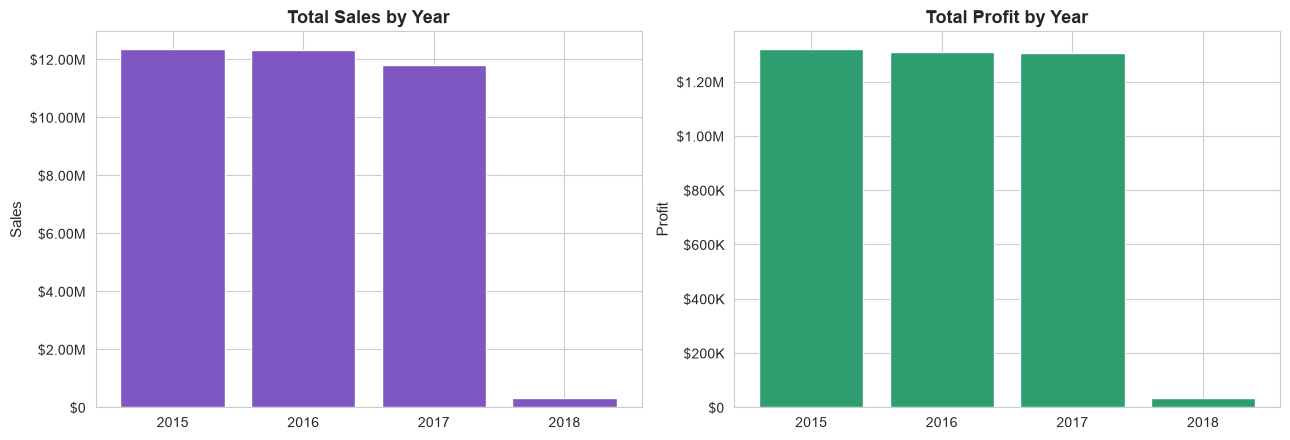

In [26]:
#Sales & Profit Analysis
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

yearly_raw = fe.groupby("Order Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).reset_index()

axes[0].bar(yearly_raw["Order Year"].astype(str), yearly_raw["Sales"], color=COLOR_PRIMARY)
axes[0].set_title("Total Sales by Year")
axes[0].set_ylabel("Sales")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[1].bar(yearly_raw["Order Year"].astype(str), yearly_raw["Profit"], color=COLOR_POSITIVE)
axes[1].set_title("Total Profit by Year")
axes[1].set_ylabel("Profit")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

plt.tight_layout()
plt.show()


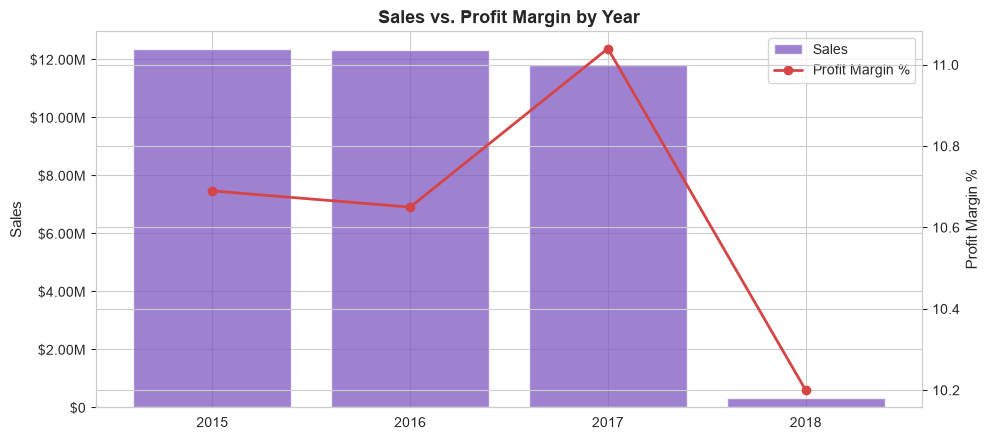

In [27]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

ax1.bar(yearly_kpi["Order Year"].astype(str), yearly_raw["Sales"], color=COLOR_PRIMARY, alpha=0.75, label="Sales")
ax2.plot(yearly_kpi["Order Year"].astype(str), yearly_kpi["Profit Margin %"], color=COLOR_NEGATIVE, marker="o", linewidth=2, label="Profit Margin %")

ax1.set_ylabel("Sales")
ax2.set_ylabel("Profit Margin %")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
ax1.set_title("Sales vs. Profit Margin by Year")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()


In [28]:
#Time-Series Analysis
monthly = fe.groupby(fe["order date (DateOrders)"].dt.to_period("M")).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order Id", "nunique"),
    Order_Items=("Order Item Id", "count"),
).reset_index()
monthly["order date (DateOrders)"] = monthly["order date (DateOrders)"].dt.to_timestamp()

# Flag months whose order-item volume falls materially below the dataset's typical monthly level
typical_volume = monthly["Order_Items"].median()
monthly["Period"] = np.where(monthly["Order_Items"] < 0.7 * typical_volume, "Reduced coverage", "Complete")

print(f"Typical (median) monthly order-item volume: {typical_volume:,.0f}")
monthly[["order date (DateOrders)", "Order_Items", "Orders", "Period"]].tail(8)


Typical (median) monthly order-item volume: 5,217


,order date (DateOrders),Order_Items,Orders,Period
29,2017-06-01,4951,1676,Complete
30,2017-07-01,5318,1776,Complete
31,2017-08-01,5305,1768,Complete
32,2017-09-01,5189,1723,Complete
33,2017-10-01,2255,2101,Reduced coverage
34,2017-11-01,2055,2055,Reduced coverage
35,2017-12-01,2124,2124,Reduced coverage
36,2018-01-01,2123,2123,Reduced coverage


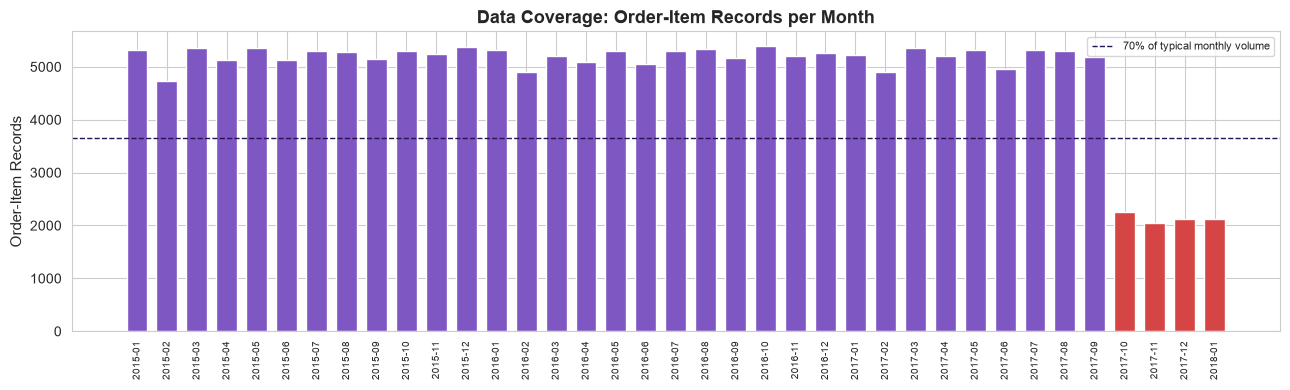

Months flagged as reduced coverage: ['2017-10', '2017-11', '2017-12', '2018-01']


In [29]:
fig, ax = plt.subplots(figsize=(13, 4))
bar_colors = [COLOR_PRIMARY if p == "Complete" else COLOR_NEGATIVE for p in monthly["Period"]]
ax.bar(monthly["order date (DateOrders)"].dt.strftime("%Y-%m"), monthly["Order_Items"], color=bar_colors, width=0.7)
ax.set_title("Data Coverage: Order-Item Records per Month")
ax.set_ylabel("Order-Item Records")
ax.axhline(0.7 * typical_volume, color=COLOR_DARK, linestyle="--", linewidth=1, label="70% of typical monthly volume")
ax.legend(fontsize=8)
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

reduced_months = monthly.loc[monthly["Period"] == "Reduced coverage", "order date (DateOrders)"].dt.strftime("%Y-%m").tolist()
print("Months flagged as reduced coverage:", reduced_months)


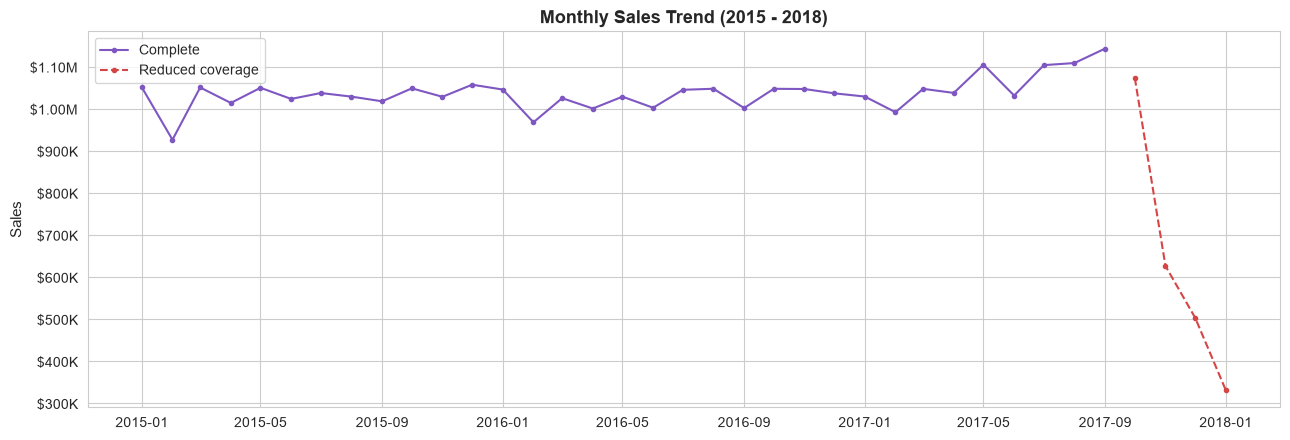

In [30]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for period, group in monthly.groupby("Period"):
    style = "--" if period == "Reduced coverage" else "-"
    ax.plot(group["order date (DateOrders)"], group["Sales"], style, marker="o", markersize=3,
            label=period, color=COLOR_PRIMARY if period == "Complete" else COLOR_NEGATIVE)

ax.set_title("Monthly Sales Trend (2015 - 2018)")
ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
ax.legend()
plt.tight_layout()
plt.show()


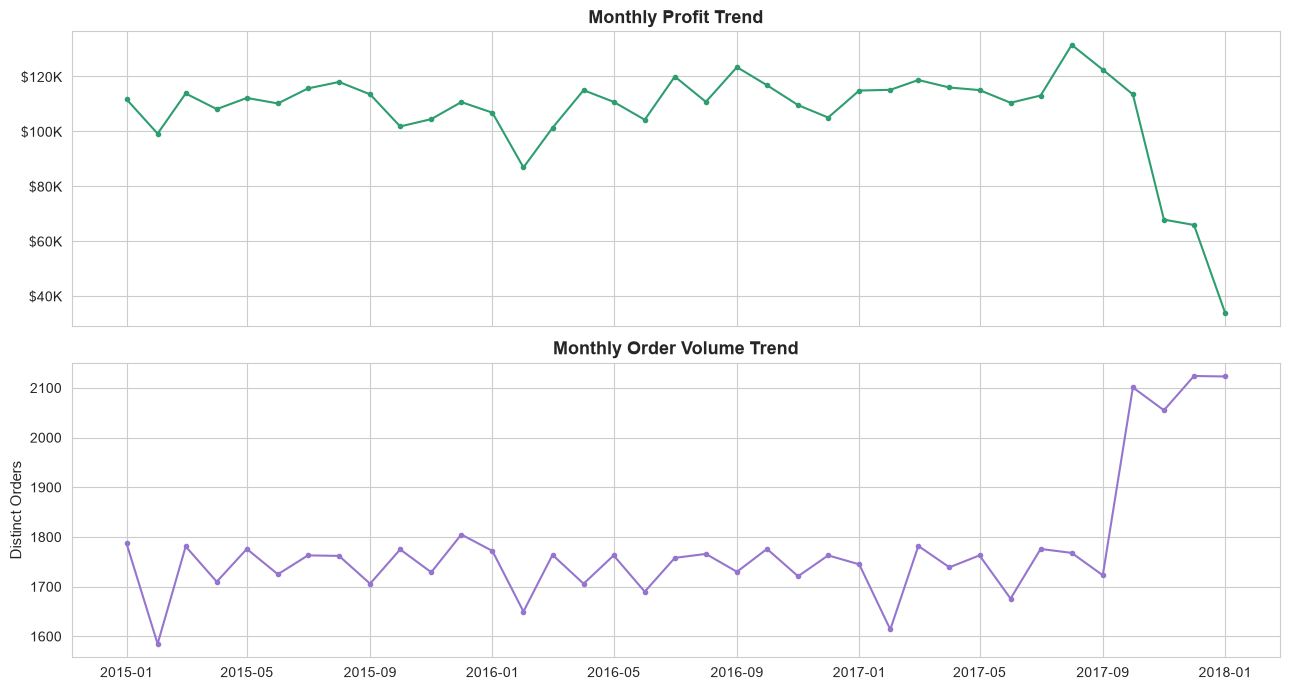

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(monthly["order date (DateOrders)"], monthly["Profit"], color=COLOR_POSITIVE, marker="o", markersize=3)
axes[0].set_title("Monthly Profit Trend")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[1].plot(monthly["order date (DateOrders)"], monthly["Orders"], color=COLOR_SECONDARY, marker="o", markersize=3)
axes[1].set_title("Monthly Order Volume Trend")
axes[1].set_ylabel("Distinct Orders")

plt.tight_layout()
plt.show()


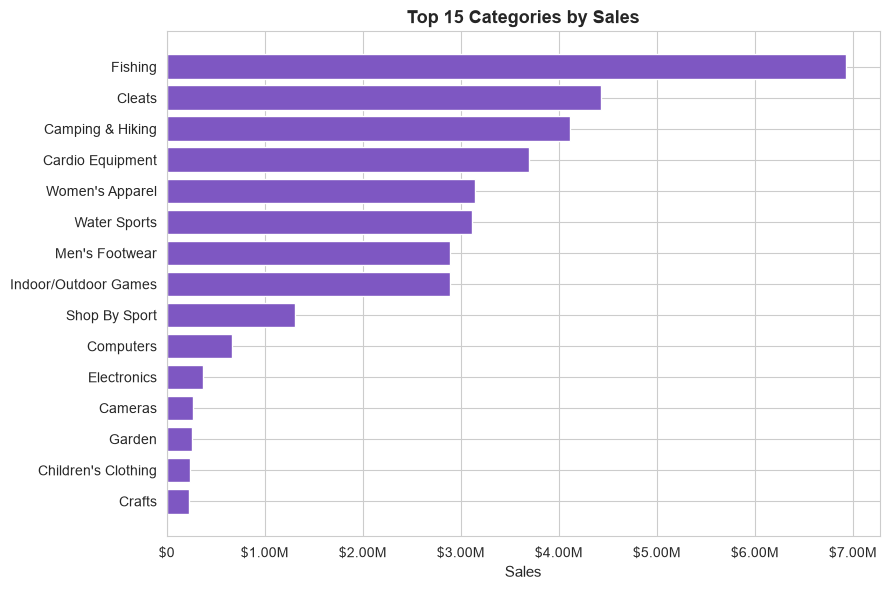

In [32]:
#Product & Category Analysis
category_perf = fe.groupby("Category Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Order Item Quantity", "sum"),
    Orders=("Order Id", "nunique"),
).reset_index()
category_perf["Profit Margin %"] = (category_perf["Profit"] / category_perf["Sales"] * 100).round(2)
category_perf = category_perf.sort_values("Sales", ascending=False)

top15_cat_sales = category_perf.head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15_cat_sales["Category Name"][::-1], top15_cat_sales["Sales"][::-1], color=COLOR_PRIMARY)
ax.set_title("Top 15 Categories by Sales")
ax.set_xlabel("Sales")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
plt.tight_layout()
plt.show()


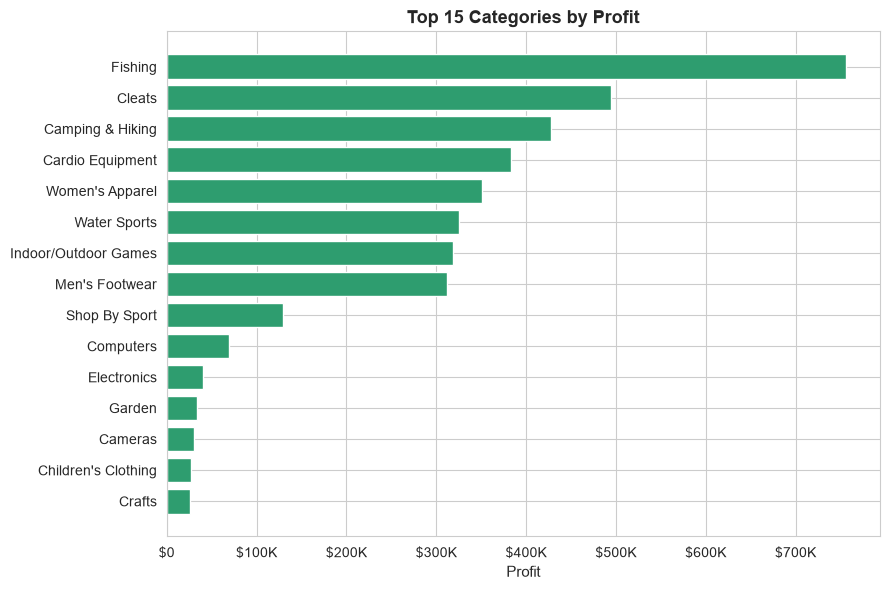

In [33]:
top15_cat_profit = category_perf.sort_values("Profit", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
colors = [COLOR_POSITIVE if p >= 0 else COLOR_NEGATIVE for p in top15_cat_profit["Profit"][::-1]]
ax.barh(top15_cat_profit["Category Name"][::-1], top15_cat_profit["Profit"][::-1], color=colors)
ax.set_title("Top 15 Categories by Profit")
ax.set_xlabel("Profit")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
plt.tight_layout()
plt.show()


In [34]:
top_sales_cats = set(category_perf.sort_values("Sales", ascending=False).head(10)["Category Name"])
top_profit_cats = set(category_perf.sort_values("Profit", ascending=False).head(10)["Category Name"])

print("In top 10 by Sales but NOT top 10 by Profit:", top_sales_cats - top_profit_cats)
print("In top 10 by Profit but NOT top 10 by Sales:", top_profit_cats - top_sales_cats)
print("In both top 10 lists:", top_sales_cats & top_profit_cats)


In top 10 by Sales but NOT top 10 by Profit: set()
In top 10 by Profit but NOT top 10 by Sales: set()
In both top 10 lists: {'Computers', 'Cardio Equipment', 'Fishing', 'Cleats', 'Camping & Hiking', 'Water Sports', 'Indoor/Outdoor Games', "Men's Footwear", "Women's Apparel", 'Shop By Sport'}


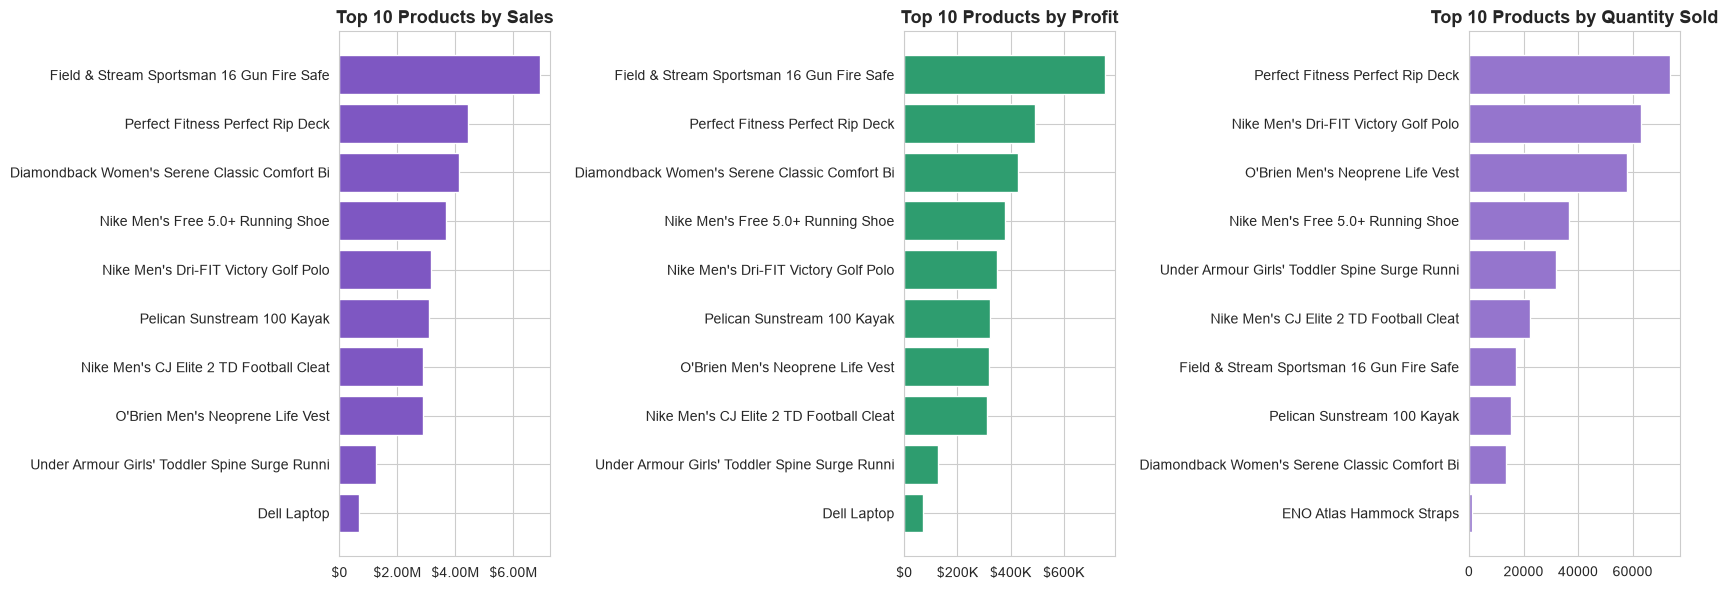

In [35]:
product_perf = fe.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Order Item Quantity", "sum"),
).reset_index()

top10_prod_sales = product_perf.sort_values("Sales", ascending=False).head(10)
top10_prod_profit = product_perf.sort_values("Profit", ascending=False).head(10)
top10_prod_qty = product_perf.sort_values("Quantity", ascending=False).head(10)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

axes[0].barh(top10_prod_sales["Product Name"][::-1], top10_prod_sales["Sales"][::-1], color=COLOR_PRIMARY)
axes[0].set_title("Top 10 Products by Sales")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[1].barh(top10_prod_profit["Product Name"][::-1], top10_prod_profit["Profit"][::-1], color=COLOR_POSITIVE)
axes[1].set_title("Top 10 Products by Profit")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[2].barh(top10_prod_qty["Product Name"][::-1], top10_prod_qty["Quantity"][::-1], color=COLOR_SECONDARY)
axes[2].set_title("Top 10 Products by Quantity Sold")

plt.tight_layout()
plt.show()


In [36]:
# Profitability matrix: classify categories by Sales level vs Margin level (median split)
sales_median = category_perf["Sales"].median()
margin_median = category_perf["Profit Margin %"].median()

def quadrant(row):
    high_sales = row["Sales"] >= sales_median
    high_margin = row["Profit Margin %"] >= margin_median
    if high_sales and high_margin:
        return "High Sales / High Margin"
    if high_sales and not high_margin:
        return "High Sales / Low Margin"
    if not high_sales and high_margin:
        return "Low Sales / High Margin"
    return "Low Sales / Low Margin"

category_perf["Quadrant"] = category_perf.apply(quadrant, axis=1)

fig = px.scatter(
    category_perf, x="Sales", y="Profit Margin %", size="Quantity", color="Quadrant",
    hover_name="Category Name", title="Category Profitability Matrix: Sales vs. Profit Margin",
    labels={"Sales": "Total Sales ($)"}, color_discrete_sequence=PLOTLY_QUALITATIVE,
)
fig.add_vline(x=sales_median, line_dash="dash", line_color="gray")
fig.add_hline(y=margin_median, line_dash="dash", line_color="gray")
fig.update_layout(height=520)
fig.show()


In [37]:
category_perf["Quadrant"].value_counts().to_frame(name="Category Count")

,Category Count
Quadrant,
High Sales / High Margin,13
Low Sales / Low Margin,13
High Sales / Low Margin,12
Low Sales / High Margin,12


In [38]:
#Customer Analysis
segment_perf = fe.groupby("Customer Segment").agg(
    Customers=("Customer Id", "nunique"),
    Orders=("Order Id", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
).reset_index()
segment_perf["Avg Order Value"] = segment_perf["Sales"] / segment_perf["Orders"]
segment_perf["Sales Share %"] = (segment_perf["Sales"] / segment_perf["Sales"].sum() * 100).round(1)
segment_perf = segment_perf.sort_values("Sales", ascending=False)
segment_perf


,Customer Segment,Customers,Orders,Sales,Profit,Avg Order Value,Sales Share %
0,Consumer,10695,34119,1.909579e+07,2.073488e+06,559.682000,51.9
1,Corporate,6239,19856,1.116841e+07,1.202575e+06,562.470127,30.4
2,Home Office,3718,11777,6.520538e+06,6.908403e+05,553.667149,17.7


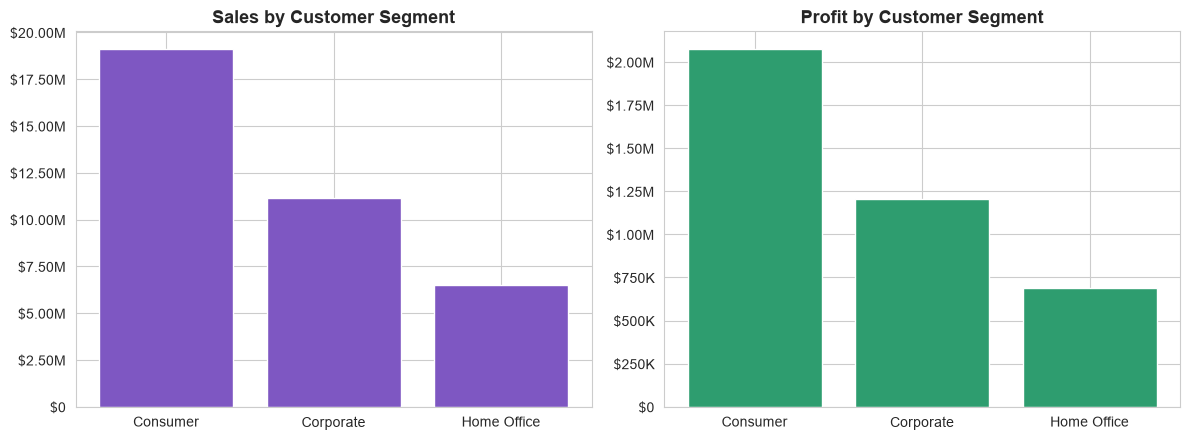

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(segment_perf["Customer Segment"], segment_perf["Sales"], color=COLOR_PRIMARY)
axes[0].set_title("Sales by Customer Segment")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[1].bar(segment_perf["Customer Segment"], segment_perf["Profit"], color=COLOR_POSITIVE)
axes[1].set_title("Profit by Customer Segment")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

plt.tight_layout()
plt.show()


In [40]:
# Repeat customer rate (defined as customers with > 1 distinct Order Id)
customer_orders = fe.groupby("Customer Id")["Order Id"].nunique()
repeat_customers = (customer_orders > 1).sum()
total_unique_customers = customer_orders.shape[0]
repeat_rate = repeat_customers / total_unique_customers * 100

print(f"Total customers: {total_unique_customers:,}")
print(f"Repeat customers (>1 distinct order): {repeat_customers:,}")
print(f"Repeat customer rate: {repeat_rate:.2f}%")


Total customers: 20,652
Repeat customers (>1 distinct order): 11,768
Repeat customer rate: 56.98%


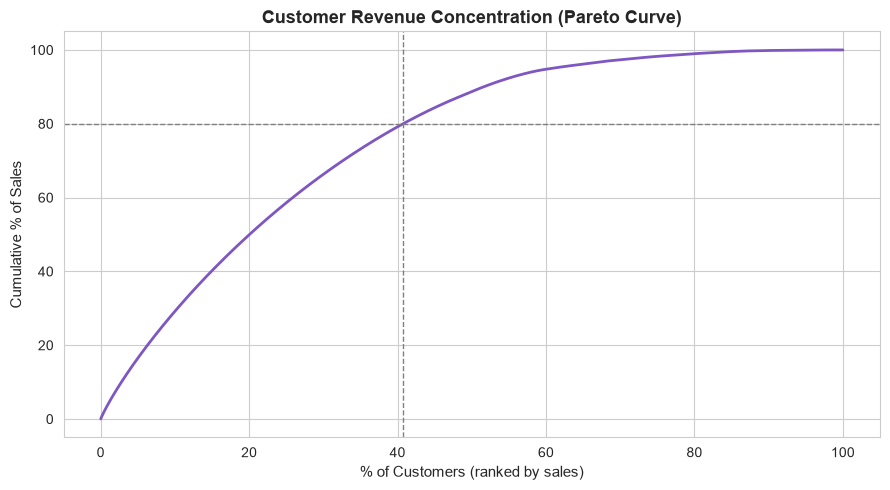

40.7% of customers generate 80% of total sales.


In [41]:
# Pareto analysis — what % of customers generate what % of sales?
customer_sales = fe.groupby("Customer Id")["Sales"].sum().sort_values(ascending=False).reset_index()
customer_sales["Cumulative Sales %"] = customer_sales["Sales"].cumsum() / customer_sales["Sales"].sum() * 100
customer_sales["Customer Rank %"] = (np.arange(1, len(customer_sales) + 1) / len(customer_sales)) * 100

pct_customers_for_80pct_sales = customer_sales[customer_sales["Cumulative Sales %"] >= 80].iloc[0]["Customer Rank %"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(customer_sales["Customer Rank %"], customer_sales["Cumulative Sales %"], color=COLOR_PRIMARY, linewidth=2)
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.axvline(pct_customers_for_80pct_sales, color="gray", linestyle="--", linewidth=1)
ax.set_title("Customer Revenue Concentration (Pareto Curve)")
ax.set_xlabel("% of Customers (ranked by sales)")
ax.set_ylabel("Cumulative % of Sales")
plt.tight_layout()
plt.show()

print(f"{pct_customers_for_80pct_sales:.1f}% of customers generate 80% of total sales.")


In [42]:
#Market Analysis
market_perf = fe.groupby("Market").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order Id", "nunique"),
    Customers=("Customer Id", "nunique"),
).reset_index()
market_perf["Profit Margin %"] = (market_perf["Profit"] / market_perf["Sales"] * 100).round(2)
market_perf = market_perf.sort_values("Sales", ascending=False)
market_perf


,Market,Sales,Profit,Orders,Customers,Profit Margin %
1,Europe,1.087240e+07,1.169443e+06,18561,11657,10.76
2,LATAM,1.027761e+07,1.123322e+06,17181,9325,10.93
3,Pacific Asia,8.273744e+06,8.577534e+05,17577,13267,10.37
4,USCA,5.066529e+06,5.643138e+05,8579,6256,11.14
0,Africa,2.294453e+06,2.520712e+05,3854,3311,10.99


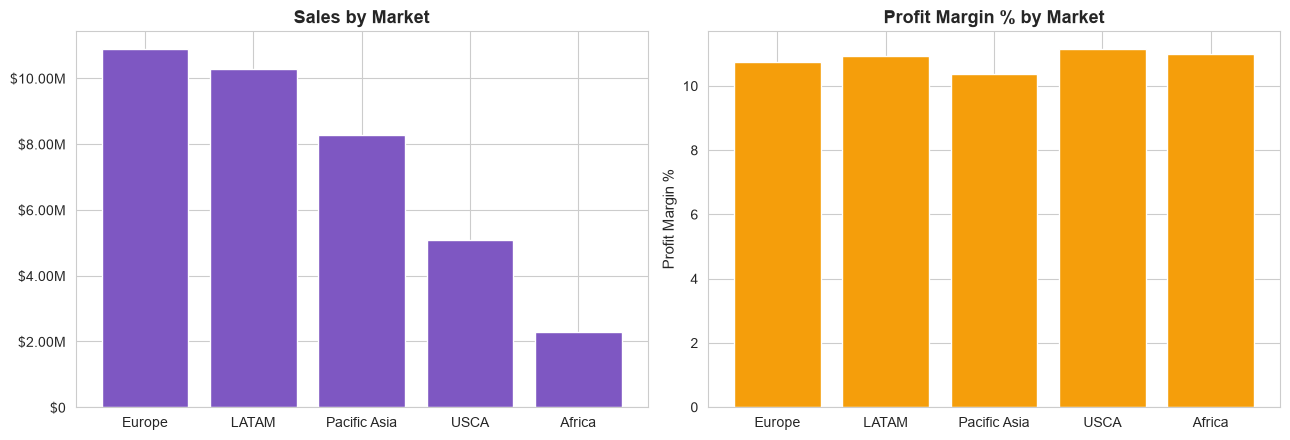

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(market_perf["Market"], market_perf["Sales"], color=COLOR_PRIMARY)
axes[0].set_title("Sales by Market")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))

axes[1].bar(market_perf["Market"], market_perf["Profit Margin %"], color=COLOR_HIGHLIGHT)
axes[1].set_title("Profit Margin % by Market")
axes[1].set_ylabel("Profit Margin %")

plt.tight_layout()
plt.show()


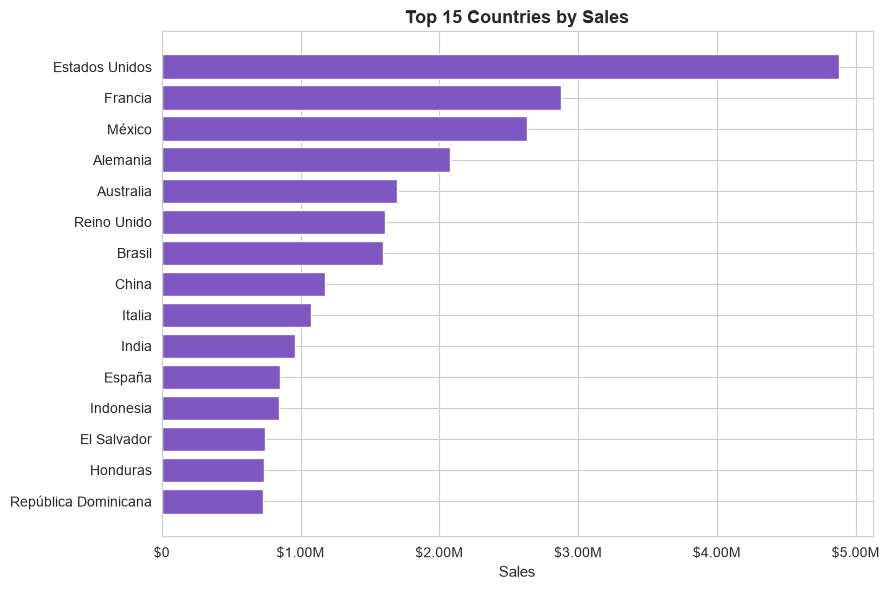

In [44]:
#Geographic Analysis
country_perf = fe.groupby("Order Country").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order Id", "nunique"),
).reset_index()

top15_country_sales = country_perf.sort_values("Sales", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15_country_sales["Order Country"][::-1], top15_country_sales["Sales"][::-1], color=COLOR_PRIMARY)
ax.set_title("Top 15 Countries by Sales")
ax.set_xlabel("Sales")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
plt.tight_layout()
plt.show()


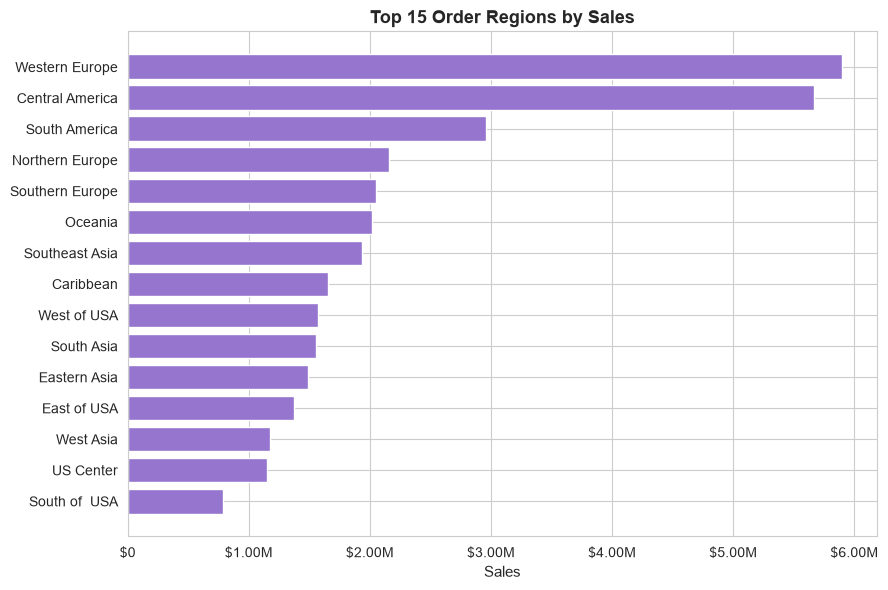

In [45]:
region_perf = fe.groupby(["Market", "Order Region"]).agg(Sales=("Sales", "sum")).reset_index()
region_perf = region_perf.sort_values("Sales", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(region_perf["Order Region"][::-1], region_perf["Sales"][::-1], color=COLOR_SECONDARY)
ax.set_title("Top 15 Order Regions by Sales")
ax.set_xlabel("Sales")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
plt.tight_layout()
plt.show()


In [46]:
fig = px.choropleth(
    country_perf, locations="Order Country", locationmode="country names", color="Sales",
    color_continuous_scale="Viridis", title="Sales by Country (Choropleth)",
)
fig.update_layout(height=480, margin=dict(l=0, r=0, t=40, b=0))
fig.show()


In [47]:
#Shipping Analysis
shipping_perf = fe.groupby("Shipping Mode").agg(
    Orders=("Order Id", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Shipping_Days=("Shipping Duration", "mean"),
).reset_index()
shipping_perf["Order Share %"] = (shipping_perf["Orders"] / shipping_perf["Orders"].sum() * 100).round(1)
shipping_perf["Avg_Shipping_Days"] = shipping_perf["Avg_Shipping_Days"].round(2)
shipping_perf = shipping_perf.sort_values("Orders", ascending=False)
shipping_perf


,Shipping Mode,Orders,Sales,Profit,Avg_Shipping_Days,Order Share %
3,Standard Class,39324,2.202239e+07,2.370454e+06,4.00,59.8
2,Second Class,12778,7.145445e+06,7.503082e+05,3.99,19.4
0,First Class,10079,5.674370e+06,6.431219e+05,2.00,15.3
1,Same Day,3571,1.942529e+06,2.030184e+05,0.48,5.4


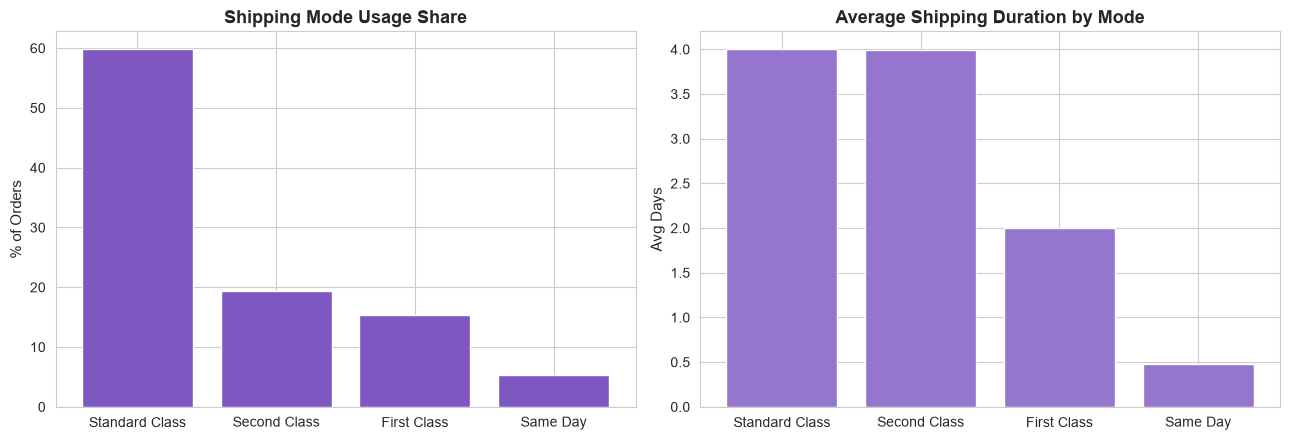

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(shipping_perf["Shipping Mode"], shipping_perf["Order Share %"], color=COLOR_PRIMARY)
axes[0].set_title("Shipping Mode Usage Share")
axes[0].set_ylabel("% of Orders")

axes[1].bar(shipping_perf["Shipping Mode"], shipping_perf["Avg_Shipping_Days"], color=COLOR_SECONDARY)
axes[1].set_title("Average Shipping Duration by Mode")
axes[1].set_ylabel("Avg Days")

plt.tight_layout()
plt.show()


In [49]:
#Deliver & Logistics Analysis
status_counts = fe["Delivery Status"].value_counts()
status_pct = (status_counts / status_counts.sum() * 100).round(2)

delivery_status_summary = pd.DataFrame({
    "Order Items": status_counts,
    "% of Order Items": status_pct
})
delivery_status_summary


,Order Items,% of Order Items
Delivery Status,,
Late delivery,98977,54.83
Advance shipping,41592,23.04
Shipping on time,32196,17.84
Shipping canceled,7754,4.30


In [50]:
late_rate = (fe["Late_delivery_risk"] == 1).mean() * 100
on_time_or_early_rate = fe["Delivery Status"].isin(["Advance shipping", "Shipping on time"]).mean() * 100
canceled_rate = (fe["Delivery Status"] == "Shipping canceled").mean() * 100

print(f"Late Delivery Rate: {late_rate:.2f}%")
print(f"On-Time-or-Early Delivery Rate (Advance shipping + Shipping on time): {on_time_or_early_rate:.2f}%")
print(f"Shipment Canceled Rate: {canceled_rate:.2f}%")


Late Delivery Rate: 54.83%
On-Time-or-Early Delivery Rate (Advance shipping + Shipping on time): 40.88%
Shipment Canceled Rate: 4.30%


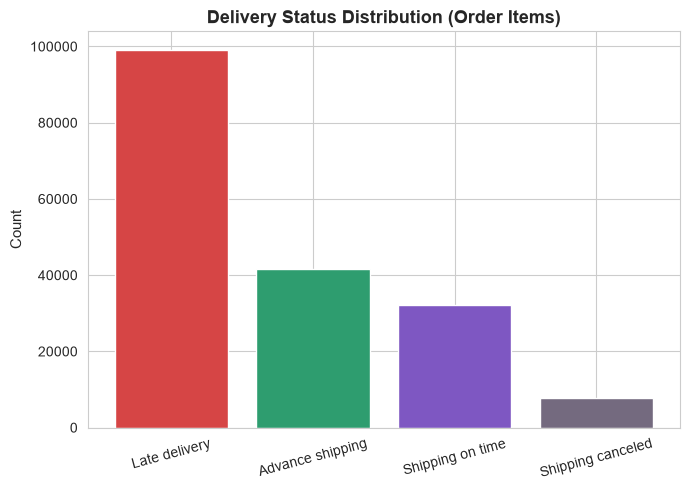

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
colors_map = {"Late delivery": COLOR_NEGATIVE, "Advance shipping": COLOR_POSITIVE,
              "Shipping on time": COLOR_PRIMARY, "Shipping canceled": COLOR_NEUTRAL}
ax.bar(status_counts.index, status_counts.values, color=[colors_map[s] for s in status_counts.index])
ax.set_title("Delivery Status Distribution (Order Items)")
ax.set_ylabel("Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


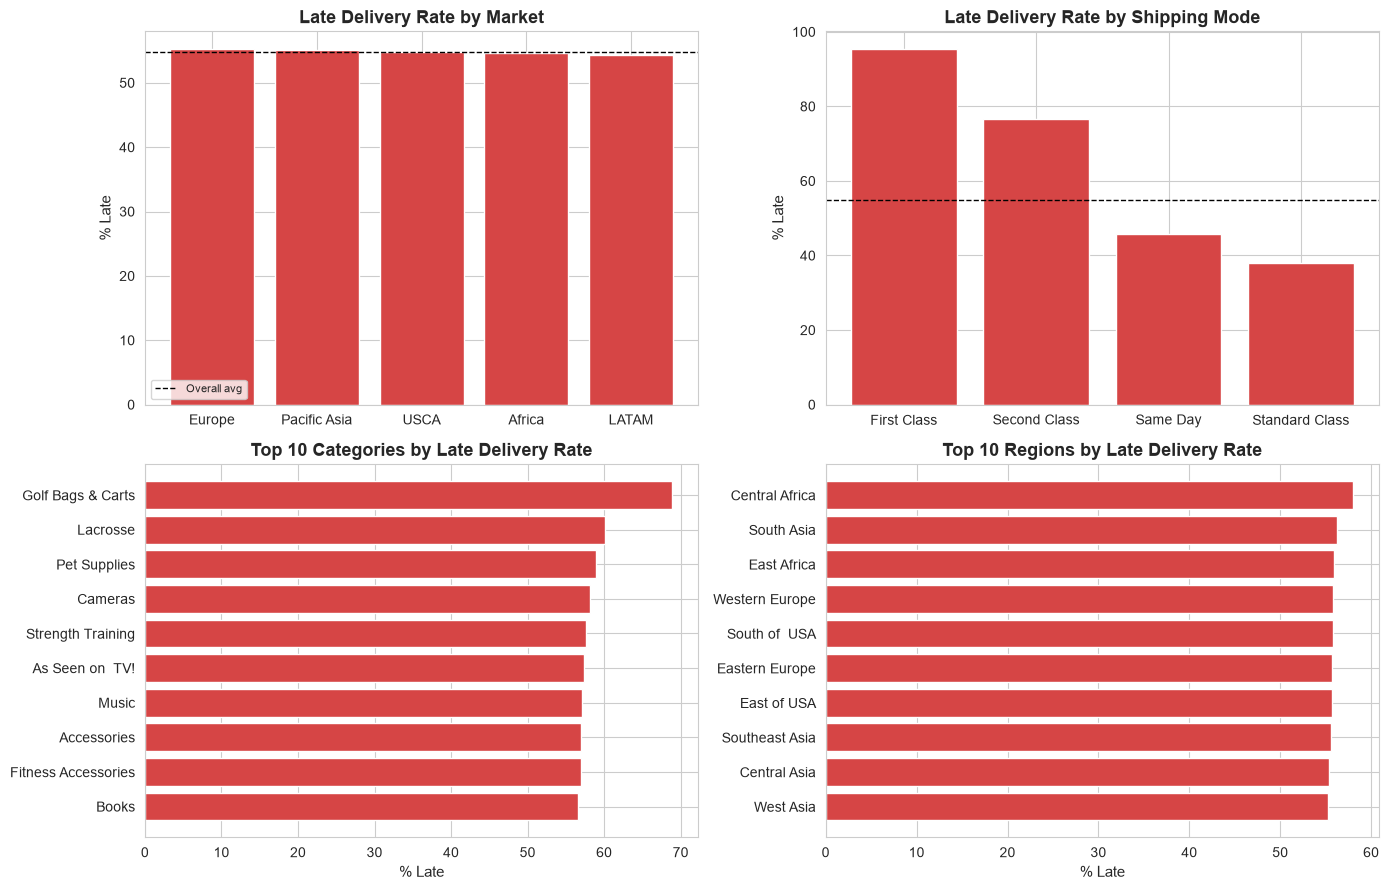

In [52]:
# Late delivery rate by Market, Category, Shipping Mode, Region
def late_rate_by(col, top_n=None):
    g = fe.groupby(col)["Late_delivery_risk"].mean().mul(100).round(2).sort_values(ascending=False)
    return g.head(top_n) if top_n else g

late_by_market = late_rate_by("Market")
late_by_shipmode = late_rate_by("Shipping Mode")
late_by_category = late_rate_by("Category Name", top_n=10)
late_by_region = late_rate_by("Order Region", top_n=10)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0,0].bar(late_by_market.index, late_by_market.values, color=COLOR_NEGATIVE)
axes[0,0].set_title("Late Delivery Rate by Market")
axes[0,0].set_ylabel("% Late")
axes[0,0].axhline(late_rate, color="black", linestyle="--", linewidth=1, label="Overall avg")
axes[0,0].legend(fontsize=8)

axes[0,1].bar(late_by_shipmode.index, late_by_shipmode.values, color=COLOR_NEGATIVE)
axes[0,1].set_title("Late Delivery Rate by Shipping Mode")
axes[0,1].set_ylabel("% Late")
axes[0,1].axhline(late_rate, color="black", linestyle="--", linewidth=1)

axes[1,0].barh(late_by_category.index[::-1], late_by_category.values[::-1], color=COLOR_NEGATIVE)
axes[1,0].set_title("Top 10 Categories by Late Delivery Rate")
axes[1,0].set_xlabel("% Late")

axes[1,1].barh(late_by_region.index[::-1], late_by_region.values[::-1], color=COLOR_NEGATIVE)
axes[1,1].set_title("Top 10 Regions by Late Delivery Rate")
axes[1,1].set_xlabel("% Late")

plt.tight_layout()
plt.show()


In [53]:
print("Late delivery rate range across Markets:", f"{late_by_market.min():.2f}% - {late_by_market.max():.2f}%")
print("Late delivery rate range across Shipping Modes:", f"{late_by_shipmode.min():.2f}% - {late_by_shipmode.max():.2f}%")
print()
print("Late delivery rate by Shipping Mode:")
print(late_by_shipmode)


Late delivery rate range across Markets: 54.36% - 55.21%
Late delivery rate range across Shipping Modes: 38.07% - 95.32%

Late delivery rate by Shipping Mode:
Shipping Mode
First Class       95.32
Second Class      76.63
Same Day          45.74
Standard Class    38.07
Name: Late_delivery_risk, dtype: float64


In [54]:
mode_schedule_check = fe.groupby("Shipping Mode").agg(
    Avg_Scheduled_Days=("Days for shipment (scheduled)", "mean"),
    Avg_Actual_Days=("Shipping Duration", "mean"),
    Late_Rate=("Late_delivery_risk", "mean"),
).round(2)
mode_schedule_check["Avg Gap (Actual - Scheduled)"] = (mode_schedule_check["Avg_Actual_Days"] - mode_schedule_check["Avg_Scheduled_Days"]).round(2)
mode_schedule_check["Late_Rate"] = (mode_schedule_check["Late_Rate"] * 100).round(2)
mode_schedule_check = mode_schedule_check.sort_values("Late_Rate", ascending=False)
mode_schedule_check


,Avg_Scheduled_Days,Avg_Actual_Days,Late_Rate,Avg Gap (Actual - Scheduled)
Shipping Mode,,,,
First Class,1.0,2.00,95.0,1.00
Second Class,2.0,3.99,77.0,1.99
Same Day,0.0,0.48,46.0,0.48
Standard Class,4.0,4.00,38.0,0.00


In [ ]:
#Advanced Business Analysis
#1) Product Revenue Concentration (Pareto Analysis)

# Calculate cumulative revenue share by product
product_sales = fe.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).reset_index()
product_sales["Cumulative Sales %"] = (product_sales["Sales"].cumsum() / product_sales["Sales"].sum()) * 100
product_sales["Product Rank %"] = (np.arange(1, len(product_sales) + 1) / len(product_sales)) * 100

# Identify threshold for 80% revenue
pareto_threshold = product_sales[product_sales["Cumulative Sales %"] >= 80].iloc[0]
n_products_for_80 = int((product_sales["Cumulative Sales %"] < 80).sum() + 1)

print(f"Pareto Analysis: {n_products_for_80} out of {len(product_sales)} products ({pareto_threshold['Product Rank %']:.2f}%) generate 80% of total revenue.")


Pareto Analysis: 8 out of 118 products (6.78%) generate 80% of total revenue.


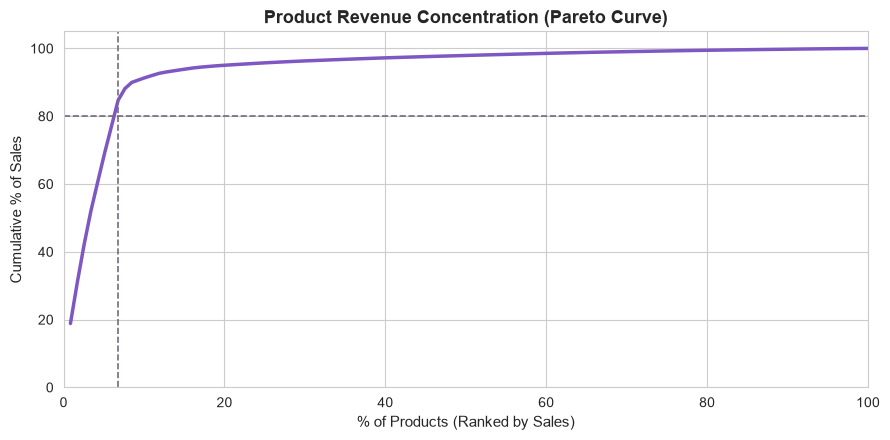

In [56]:
# Plot Pareto Concentration Curve
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(product_sales["Product Rank %"], product_sales["Cumulative Sales %"], color=COLOR_PRIMARY, linewidth=2.5)
ax.axhline(80, color=COLOR_NEUTRAL, linestyle="--", linewidth=1.2)
ax.axvline(pareto_threshold["Product Rank %"], color=COLOR_NEUTRAL, linestyle="--", linewidth=1.2)

ax.set_title("Product Revenue Concentration (Pareto Curve)")
ax.set_xlabel("% of Products (Ranked by Sales)")
ax.set_ylabel("Cumulative % of Sales")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

In [57]:
#2) Category Profitability Matrix (Quadrant Analysis)
# Aggregate category volume, revenue, and margins

category_perf = fe.groupby("Category Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Order Item Quantity", "sum")
).reset_index()
category_perf["Profit Margin %"] = (category_perf["Profit"] / category_perf["Sales"]) * 100

# Segment categories using median-split strategy
sales_median = category_perf["Sales"].median()
margin_median = category_perf["Profit Margin %"].median()

def assign_quadrant(row):
    high_sales = row["Sales"] >= sales_median
    high_margin = row["Profit Margin %"] >= margin_median
    if high_sales and high_margin: return "High Sales / High Margin"
    if high_sales and not high_margin: return "High Sales / Low Margin"
    if not high_sales and high_margin: return "Low Sales / High Margin"
    return "Low Sales / Low Margin"

category_perf["Quadrant"] = category_perf.apply(assign_quadrant, axis=1)
category_perf["Quadrant"].value_counts().to_frame(name="Category Count")


,Category Count
Quadrant,
High Sales / High Margin,13
Low Sales / Low Margin,13
Low Sales / High Margin,12
High Sales / Low Margin,12


In [58]:
# Plot Portfolio Profitability Matrix
fig = px.scatter(
    category_perf, x="Quantity", y="Profit Margin %", size="Sales", color="Quadrant",
    hover_name="Category Name", title="Category Portfolio Matrix: Volume vs. Profit Margin",
    labels={"Quantity": "Units Sold", "Profit Margin %": "Profit Margin (%)"},
    color_discrete_sequence=PLOTLY_QUALITATIVE
)
fig.add_vline(x=category_perf["Quantity"].median(), line_dash="dash", line_color="gray")
fig.add_hline(y=margin_median, line_dash="dash", line_color="gray")
fig.update_layout(height=480, legend_title_text="Strategic Quadrant", margin=dict(t=50, b=30, l=50, r=30))
fig.show()

# Statistical validation of volume vs. margin relationship
corr_coef = category_perf["Quantity"].corr(category_perf["Profit Margin %"])
print(f"Correlation between volume and profit margin: {corr_coef:.4f}")


Correlation between volume and profit margin: 0.0202


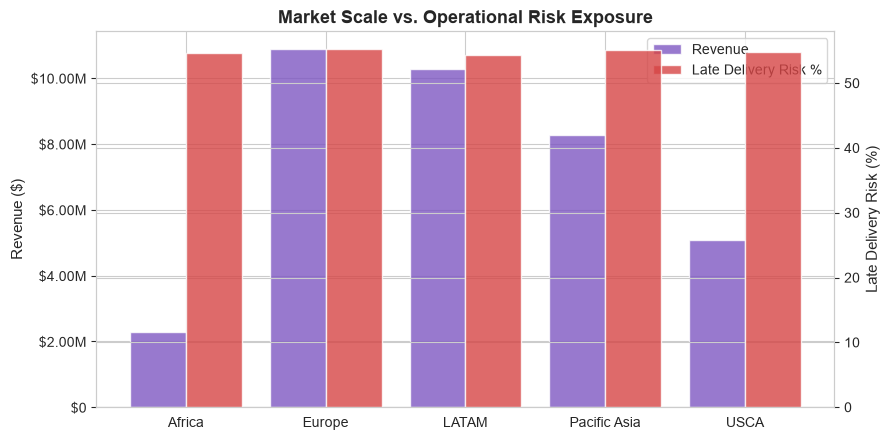

In [59]:
#3) Cross-Dimensional Logistics Risk Analysis
# Evaluate relationship between market scale and delivery failure rates

market_risk = fe.groupby("Market").agg(
    Sales=("Sales", "sum"),
    Late_Rate=("Late_delivery_risk", "mean")
).reset_index()
market_risk["Late_Rate"] *= 100

# Visualize scale vs. operational risk exposure
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax2 = ax1.twinx()
x_indices = np.arange(len(market_risk))

ax1.bar(x_indices - 0.2, market_risk["Sales"], width=0.4, color=COLOR_PRIMARY, alpha=0.8, label="Revenue")
ax2.bar(x_indices + 0.2, market_risk["Late_Rate"], width=0.4, color=COLOR_NEGATIVE, alpha=0.8, label="Late Delivery Risk %")

ax1.set_xticks(x_indices)
ax1.set_xticklabels(market_risk["Market"])
ax1.set_ylabel("Revenue ($)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(money_fmt))
ax2.set_ylabel("Late Delivery Risk (%)")
ax1.set_title("Market Scale vs. Operational Risk Exposure")

# Consolidated legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()


In [60]:
# Data Pipeline Reconciliation & Metrics Validation
# Verify pipeline logic against target reference values from Power BI

validation_metrics = [
    ("Total Sales", total_sales, 36780000, "$"),
    ("Total Profit", total_profit, 3970000, "$"),
    ("Total Orders", total_orders, 65752, "#"),
    ("Total Customers", total_customers, 20652, "#"),
    ("Total Products", total_products, 118, "#"),
    ("Quantity Sold", total_quantity, 384079, "#"),
    ("Profit Margin %", overall_margin, 10.78, "%"),
    ("Late Delivery Risk %", late_rate, 54.83, "%")
]

validation_results = []
for metric, py_val, ref_val, unit in validation_metrics:
    diff_pct = abs(py_val - ref_val) / ref_val * 100 if ref_val != 0 else 0
    status = "Verified Match" if diff_pct <= 0.5 else "Audit Required"
    
    py_str = money_label(py_val) if unit == "$" else (f"{py_val:.2f}%" if unit == "%" else f"{py_val:,.0f}")
    ref_str = money_label(ref_val) if unit == "$" else (f"{ref_val:.2f}%" if unit == "%" else f"{ref_val:,.0f}")
    
    validation_results.append([metric, py_str, ref_str, f"{diff_pct:.2f}%", status])

pd.DataFrame(validation_results, columns=["Core Metric", "Python Pipeline", "Power BI Reference", "Variance", "Reconciliation Status"])

,Core Metric,Python Pipeline,Power BI Reference,Variance,Reconciliation Status
0,Total Sales,$36.78M,$36.78M,0.01%,Verified Match
1,Total Profit,$3.97M,$3.97M,0.08%,Verified Match
2,Total Orders,"65,752","65,752",0.00%,Verified Match
3,Total Customers,"20,652","20,652",0.00%,Verified Match
4,Total Products,118,118,0.00%,Verified Match
5,Quantity Sold,"384,079","384,079",0.00%,Verified Match
6,Profit Margin %,10.78%,10.78%,0.04%,Verified Match
7,Late Delivery Risk %,54.83%,54.83%,0.00%,Verified Match


#### Main Insights & Recommendations

##### What I found in the data (Key Insights):
1. **High product risk:** We have 118 products, but only 8 of them (around 7%) bring in 80% of all our money. This is dangerous because if we have problems with these 8 products, the company will lose almost all its revenue.
2. **Big logistics problem:** More than half of our orders (54.83%) arrive late. After checking different factors, I found that it's not because of the countries or categories. The main problem is the Shipping Mode: "First Class" has a 95.32% late rate and "Second Class" has 76.63%. The windows for these shipping modes are just unrealistically short.
3. **Volume doesn't mean profit:** I checked the correlation between how many items we sell and the profit margin, and it is almost 0 (r = 0.02). This means selling more units does not mean we get a better margin. Margins depend more on discounts and prices.
4. **Europe and LATAM are the main markets:** Europe ($10.87M) and LATAM ($10.28M) generate more than 50% of our sales. Since the late delivery rate is the same everywhere, these two regions have the biggest absolute number of late orders.

##### My recommendations for the business:
1. **Fix the shipping schedule:** We need to change the promised delivery time for "First Class" and "Second Class". Right now, they are too short. If we make them realistic (more like "Standard Class"), our late delivery rate will automatically drop.
2. **Protect top products:** We need to always have extra stock for those 8 top products and find backup suppliers for them so we never run out of stock.
3. **Change prices/discounts for low-margin items:** Look at categories that have high sales but low profit (like Fishing). We need to reduce discounts on them to increase our profit margin without trying to sell more units.
4. **Focus logistics help on Europe and LATAM:** Since most of our late orders happen there because of the large volume, any fixes in shipping should start in these two markets to help the maximum number of customers first.
